# 05 — GAN alternative: translate real healthy photos into OCA

Instead of drawing a whole mouth from noise (the diffusion notebook 02), a **translation GAN** starts
from a **real healthy training photo** and changes its appearance towards OCA. Teeth, tongue, lighting and
framing come from the real photo, which usually looks far more realistic with very little OCA data.

Two GAN types (set `GAN_TYPE`):

| `GAN_TYPE` | What it is | Role |
|---|---|---|
| `"cyclegan"` | **CycleGAN** (Zhu et al. 2017): two generators Healthy⇄OCA, two PatchGAN discriminators, cycle-consistency + identity loss | **Baseline** — the method used by Theppitak et al. (2026) |
| `"stargan"` | **StarGAN-style four-domain GAN**: ONE generator `G(image, target class)` learns all four classes; the discriminator has a real/fake head **and a 4-class head**; losses = adversarial + class + cycle-reconstruction + identity | **Proposed** — learns Healthy/Benign/OPMD/OCA together, then generates OCA only |

Both use **DiffAugment** (Zhao et al. 2020) — differentiable augmentation of the discriminator's inputs,
designed for GANs trained on small datasets (you have 76 training OCA images) — and an **EMA copy of the
generator** for cleaner outputs.

**Leakage rule:** only **train** patients are used. Source photos for generation are training Healthy photos.

**Output:** `raw/SYN-<type>-xxxxx.png` (one OCA image per healthy training photo) → run **notebook 03 with
`GENERATOR = "folder"`** for quality control, then add the accepted folder to notebook 04.

**Kaggle:** GPU T4, Internet ON. ~3–4 h at 256 px with the defaults. The run is **resumable**: if the session
stops, re-run with the previous output attached as input and point `RESUME_FROM` to its checkpoint.

In [1]:
# ============================================================
# 1. CONFIG   # @CONFIG
# ============================================================
from pathlib import Path

GAN_TYPE = "stargan"          # "cyclegan" (paper baseline, Healthy->OCA) or "stargan" (proposed, four-class)

SPLIT_ROOT = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")   # flat Benign/Healthy/OCA/OPMD folders, or a train/val/test split
# Unsegmented / original photos: point SPLIT_ROOT at the folder holding Benign/Healthy/OCA/OPMD directly.
SPLIT_REFERENCE = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")  # old split -> same patients in test. None = new split
SPLIT_BY = "patient"        # keep "patient". "image" leaks patients between train and test
CACHE_MAX_SIDE = 768        # resize the big original photos once (None = use files as they are)
OUT_DIR = Path(f"/kaggle/working/gan_{GAN_TYPE}")
RESUME_FROM = None            # e.g. Path("/kaggle/input/<prev-run>/gan_stargan/checkpoint_latest.pt")

IMG_SIZE = 256
BATCH_SIZE = 4
TOTAL_ITERS = 30000
LR = 2e-4
BETAS = (0.5, 0.999)
DECAY_START_FRAC = 0.5        # learning rate decays linearly to 0 over the second half
NGF, NDF = 64, 64             # generator / discriminator width
N_RES_BLOCKS = 9              # ResNet generator blocks (9 = standard for 256 px)
EMA_DECAY = 0.999
USE_AMP = True                # mixed precision (faster on T4). Set False if losses become NaN.

# DiffAugment (small-data GAN training)
USE_DIFFAUGMENT = True
DIFFAUG_POLICY = "color,translation,cutout"

# CycleGAN losses
LAMBDA_CYC = 10.0
LAMBDA_ID = 5.0
POOL_SIZE = 50

# StarGAN losses
LAMBDA_CLS = 1.0
LAMBDA_REC = 10.0
LAMBDA_ID_STAR = 2.0
R1_GAMMA = 1.0
R1_EVERY = 16                 # lazy R1 regularisation (StyleGAN2 practice)
# How often each class appears as a REAL image, and as a TARGET class, during StarGAN training
CLASS_SAMPLING_PROBS = {"Healthy": 0.20, "Benign": 0.20, "OPMD": 0.25, "OCA": 0.35}
TARGET_SAMPLING_PROBS = {"Healthy": 0.15, "Benign": 0.20, "OPMD": 0.25, "OCA": 0.40}

SOURCE_CLASS, TARGET_CLASS = "Healthy", "OCA"
LOG_EVERY = 100
SAMPLE_EVERY = 2000
SAVE_EVERY = 5000
SEED = 42
NUM_WORKERS = 2

In [2]:
# ============================================================
# DATA HELPERS
#   SPLIT_ROOT can be EITHER
#     (a) an already-split folder:  <SPLIT_ROOT>/train|val|test/<Class>/*
#     (b) a flat class folder (e.g. the UNSEGMENTED original photos): <SPLIT_ROOT>/<Class>/*
#         -> split here, by PATIENT. If SPLIT_REFERENCE points at your old split folder, every
#            patient goes to the same train/val/test split as before (same test patients).
# ============================================================
import os, re, json, math, random, time, shutil, subprocess, sys, importlib
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True   # a few original photos are slightly truncated JPEGs; load what is there

CLASSES = ["Benign", "Healthy", "OCA", "OPMD"]      # same alphabetical order as your earlier notebooks
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
OCA_IDX, OPMD_IDX = CLASS_TO_IDX["OCA"], CLASS_TO_IDX["OPMD"]
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
_NAME_PATTERN = re.compile(r"^[A-Za-z]+-\d+")       # Zenodo names look like R-01-03, C-10-12-5


def patient_id_from_name(stem):
    """'R-01-03' -> 'R-01'  (same rule as the split notebook)."""
    parts = stem.split("-")
    return f"{parts[0]}-{parts[1]}" if len(parts) >= 2 else stem


def list_split(split_root, split):
    rows = []
    for c in CLASSES:
        d = Path(split_root) / split / c
        if not d.is_dir():
            raise FileNotFoundError(f"Missing folder: {d}  -- check SPLIT_ROOT")
        for p in sorted(d.iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                rows.append({"path": str(p), "image_name": p.stem, "cls": c, "label": CLASS_TO_IDX[c],
                             "patient_id": patient_id_from_name(p.stem), "split": split, "synthetic": False})
    return pd.DataFrame(rows)


def load_split(split_root):
    dfs = {s: list_split(split_root, s) for s in ("train", "val", "test")}

    # 1) patient leakage check (hard stop)
    pats = {s: set(df.patient_id) for s, df in dfs.items()}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        overlap = pats[a] & pats[b]
        assert not overlap, f"Patient leakage between {a} and {b}: {sorted(overlap)[:10]}"

    # 2) warn if this looks like the AUGMENTED folder (oversampled copies) instead of the plain split
    odd = [n for df in dfs.values() for n in df.image_name if not _NAME_PATTERN.match(n)]
    if odd:
        print(f"WARNING: {len(odd)} file names don't look like Zenodo names (e.g. {odd[:3]}). "
              "If these are augmented/oversampled copies, point SPLIT_ROOT at the PLAIN patient-level "
              "split instead -- duplicated OCA copies make memorisation more likely and break patient IDs.")

    summary = pd.DataFrame({s: df.cls.value_counts().reindex(CLASSES).fillna(0).astype(int)
                            for s, df in dfs.items()})
    summary.loc["TOTAL"] = summary.sum()
    print("Images per split x class:")
    print(summary)
    print("Patients per split:", {s: len(p) for s, p in pats.items()})
    print("Patient leakage across train/val/test: NONE (checked)")
    return dfs


def _is_presplit(root):
    return all((Path(root) / s).is_dir() for s in ("train", "val", "test"))


def list_flat(root):
    rows = []
    for c in CLASSES:
        d = Path(root) / c
        if not d.is_dir():
            raise FileNotFoundError(f"Missing class folder: {d}  -- check SPLIT_ROOT")
        for p in sorted(d.rglob("*")):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                rows.append({"path": str(p), "image_name": p.stem, "cls": c, "label": CLASS_TO_IDX[c],
                             "patient_id": patient_id_from_name(p.stem), "synthetic": False})
    df = pd.DataFrame(rows)
    dup = df.image_name.duplicated(keep=False)
    if dup.any():
        print(f"WARNING: {dup.sum()} images share a file name (e.g. {df.image_name[dup].tolist()[:3]}); keeping all.")
    return df


def _group_split(df, seed, folds=6):
    """Patient-level split ~4/6 train, 1/6 val, 1/6 test (≈67/17/17), stratified by class."""
    from sklearn.model_selection import StratifiedGroupKFold
    sgkf = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    fold = np.zeros(len(df), int)
    for k, (_, idx) in enumerate(sgkf.split(df, df.label, groups=df.patient_id)):
        fold[idx] = k
    return np.where(fold == 0, "test", np.where(fold == 1, "val", "train"))


def _image_split(df, seed):
    from sklearn.model_selection import train_test_split
    idx = np.arange(len(df))
    tr, rest = train_test_split(idx, test_size=1 / 3, stratify=df.label, random_state=seed)
    va, te = train_test_split(rest, test_size=0.5, stratify=df.label.values[rest], random_state=seed)
    out = np.empty(len(df), object); out[tr], out[va], out[te] = "train", "val", "test"
    return out


def cache_resized(df, cache_dir, max_side):
    """Original photos are large (several MB each). Resize once (long side = max_side, aspect kept,
    EXIF rotation applied) into a local cache so every epoch doesn't decode full-size JPEGs."""
    from PIL import Image, ImageOps
    from concurrent.futures import ThreadPoolExecutor
    cache_dir = Path(cache_dir); cache_dir.mkdir(parents=True, exist_ok=True)

    def one(row):
        dst = cache_dir / row.cls / f"{row.image_name}.jpg"
        if not dst.exists():
            try:
                dst.parent.mkdir(parents=True, exist_ok=True)
                im = Image.open(row.path)
                try:
                    im = ImageOps.exif_transpose(im)
                except Exception:
                    pass                      # broken EXIF block -> keep the image as stored
                im = im.convert("RGB")
                im.thumbnail((max_side, max_side), Image.BICUBIC)
                im.save(dst, quality=95)
            except Exception as e:
                print(f"  SKIPPING unreadable image {row.path}: {e}")
                return None
        return str(dst)

    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        paths = list(ex.map(one, df.itertuples()))
    df = df.copy(); df["path"] = paths
    bad = df.path.isna()
    if bad.any():
        print(f"  {bad.sum()} unreadable images dropped: {df.image_name[bad].tolist()}")
        df = df[~bad].reset_index(drop=True)
    print(f"Cached {len(df)} images at long side <= {max_side}px in {cache_dir} ({time.time() - t0:.0f}s)")
    return df


def load_data(split_root, split_reference=None, split_by="patient", cache_max_side=None, seed=42,
              cache_dir="/tmp/img_cache"):
    """Returns {'train': df, 'val': df, 'test': df}. Same result in every notebook (deterministic)."""
    if _is_presplit(split_root):
        dfs = load_split(split_root)
    else:
        df = list_flat(split_root)
        print(f"Flat dataset: {len(df)} images, {df.patient_id.nunique()} patients -> splitting here (by {split_by})")
        if split_by == "image":
            print("WARNING: IMAGE-level split. Photos of the same patient can land in both train and test, "
                  "so test scores will be optimistic and the memorisation check in 03 becomes meaningless. "
                  "Use split_by='patient' for thesis numbers.")
            df["split"] = _image_split(df, seed)
        elif split_reference is not None and _is_presplit(split_reference):
            ref = pd.concat([list_split(split_reference, s) for s in ("train", "val", "test")])
            pat2split = ref.groupby("patient_id").split.first().to_dict()
            df["split"] = df.patient_id.map(pat2split)
            new = df.split.isna()
            print(f"Copied split from SPLIT_REFERENCE for {df.patient_id[~new].nunique()} patients "
                  f"({(~new).sum()} images); {df.patient_id[new].nunique()} patients not in reference.")
            if new.any():
                sub = df[new]
                df.loc[new, "split"] = (_group_split(sub, seed) if sub.patient_id.nunique() >= 6 else "train")
        else:
            df["split"] = _group_split(df, seed)
        dfs = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
        pats = {s: set(d.patient_id) for s, d in dfs.items()}
        if split_by != "image":
            for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
                assert not (pats[a] & pats[b]), f"Patient leakage between {a} and {b}"
        summary = pd.DataFrame({s: d.cls.value_counts().reindex(CLASSES).fillna(0).astype(int) for s, d in dfs.items()})
        summary.loc["TOTAL"] = summary.sum()
        print("Images per split x class:"); print(summary)
        print("Patients per split:", {s: len(p) for s, p in pats.items()})
        try:
            pd.concat(dfs.values()).to_csv("split_assignment.csv", index=False)
        except OSError:
            pass
    if cache_max_side:
        dfs = {s: cache_resized(d, cache_dir, cache_max_side) for s, d in dfs.items()}
    return dfs


def ensure_package(module, pip_name=None):
    """Install a package only if it is missing (Kaggle needs Internet ON for this)."""
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])


def remove_old_torchao(min_version=(0, 16)):
    """Kaggle ships torchao 0.10; recent peft refuses to inject LoRA if an old torchao is installed.
    These notebooks don't use torchao, so an old copy is simply uninstalled.
    Must run BEFORE peft is imported (if peft was already imported: restart the kernel)."""
    import importlib.metadata as md
    try:
        v = md.version("torchao")
    except md.PackageNotFoundError:
        return
    parts = tuple(int(x) for x in re.findall(r"\d+", v)[:2])
    if parts < min_version:
        if "peft" in sys.modules:
            print("WARNING: peft is already imported -- restart the kernel after this cell, then Run All.")
        subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"])
        print(f"Removed incompatible torchao {v} (not needed by these notebooks).")


def seed_everything(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [3]:
# ============================================================
# 2. IMPORTS + DATA (train patients only)
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
from torchvision.utils import save_image, make_grid
from PIL import Image
import matplotlib.pyplot as plt
import copy

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = USE_AMP and DEVICE.type == "cuda"
print("Device:", DEVICE, "| torch", torch.__version__, "| GAN:", GAN_TYPE, "| AMP:", AMP)
seed_everything(SEED)
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "samples").mkdir(exist_ok=True)
(OUT_DIR / "raw").mkdir(exist_ok=True)

dfs = load_data(SPLIT_ROOT, SPLIT_REFERENCE, SPLIT_BY, CACHE_MAX_SIDE)
train_df = dfs["train"].reset_index(drop=True)       # val/test never used here
N_CLS = len(CLASSES)

TRAIN_TF = T.Compose([T.Resize((int(IMG_SIZE * 1.12), int(IMG_SIZE * 1.12)), interpolation=T.InterpolationMode.BICUBIC),
                      T.RandomCrop(IMG_SIZE), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize([0.5] * 3, [0.5] * 3)])
EVAL_TF = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC),
                     T.ToTensor(), T.Normalize([0.5] * 3, [0.5] * 3)])


class Images(Dataset):
    def __init__(self, df, tf):
        self.paths, self.labels, self.tf = df["path"].tolist(), df["label"].astype(int).tolist(), tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]


def infinite_loader(df, weights=None):
    n = TOTAL_ITERS * BATCH_SIZE + 64
    if weights is None:
        sampler = WeightedRandomSampler(torch.ones(len(df), dtype=torch.double), n, replacement=True,
                                        generator=torch.Generator().manual_seed(SEED))
    else:
        sampler = WeightedRandomSampler(torch.tensor(weights, dtype=torch.double), n, replacement=True,
                                        generator=torch.Generator().manual_seed(SEED))
    return iter(DataLoader(Images(df, TRAIN_TF), batch_size=BATCH_SIZE, sampler=sampler,
                           num_workers=NUM_WORKERS, drop_last=True))


if GAN_TYPE == "cyclegan":
    dom_a = train_df[train_df.cls == SOURCE_CLASS].reset_index(drop=True)
    dom_b = train_df[train_df.cls == TARGET_CLASS].reset_index(drop=True)
    it_a, it_b = infinite_loader(dom_a), infinite_loader(dom_b)
    print(f"Domain A ({SOURCE_CLASS}): {len(dom_a)} images | Domain B ({TARGET_CLASS}): {len(dom_b)} images")
else:
    counts = train_df["cls"].value_counts()
    w = train_df["cls"].map(lambda c: CLASS_SAMPLING_PROBS[c] / counts[c]).values
    it_all = infinite_loader(train_df, w)
    TGT_P = torch.tensor([TARGET_SAMPLING_PROBS[c] for c in CLASSES], dtype=torch.float)
    print("Real-image sampling:", CLASS_SAMPLING_PROBS, "| target-class sampling:", TARGET_SAMPLING_PROBS)

Device: cuda | torch 2.11.0+cu128 | GAN: stargan | AMP: True
Flat dataset: 3000 images, 714 patients -> splitting here (by patient)
Copied split from SPLIT_REFERENCE for 714 patients (3000 images); 0 patients not in reference.
Images per split x class:
         train  val  test
cls                      
Benign     492  128   128
Healthy    481  123   125
OCA         76   16    37
OPMD       884  250   260
TOTAL     1933  517   550
Patients per split: {'train': 476, 'val': 119, 'test': 119}
Cached 1933 images at long side <= 768px in /tmp/img_cache (134s)
Cached 517 images at long side <= 768px in /tmp/img_cache (41s)
Cached 550 images at long side <= 768px in /tmp/img_cache (40s)
Real-image sampling: {'Healthy': 0.2, 'Benign': 0.2, 'OPMD': 0.25, 'OCA': 0.35} | target-class sampling: {'Healthy': 0.15, 'Benign': 0.2, 'OPMD': 0.25, 'OCA': 0.4}


In [4]:
# ============================================================
# 3. NETWORKS + DiffAugment
# ============================================================
class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.body = nn.Sequential(nn.ReflectionPad2d(1), nn.Conv2d(ch, ch, 3), nn.InstanceNorm2d(ch, affine=True),
                                  nn.ReLU(True), nn.ReflectionPad2d(1), nn.Conv2d(ch, ch, 3),
                                  nn.InstanceNorm2d(ch, affine=True))

    def forward(self, x):
        return x + self.body(x)


class ResnetGenerator(nn.Module):
    """CycleGAN-style ResNet generator. n_cond > 0 -> StarGAN conditioning (one-hot class maps concatenated)."""

    def __init__(self, n_cond=0, ngf=NGF, n_res=N_RES_BLOCKS):
        super().__init__()
        self.n_cond = n_cond
        L = [nn.ReflectionPad2d(3), nn.Conv2d(3 + n_cond, ngf, 7), nn.InstanceNorm2d(ngf, affine=True), nn.ReLU(True)]
        ch = ngf
        for _ in range(2):
            L += [nn.Conv2d(ch, ch * 2, 3, 2, 1), nn.InstanceNorm2d(ch * 2, affine=True), nn.ReLU(True)]
            ch *= 2
        L += [ResBlock(ch) for _ in range(n_res)]
        for _ in range(2):
            L += [nn.ConvTranspose2d(ch, ch // 2, 3, 2, 1, output_padding=1), nn.InstanceNorm2d(ch // 2, affine=True),
                  nn.ReLU(True)]
            ch //= 2
        L += [nn.ReflectionPad2d(3), nn.Conv2d(ch, 3, 7), nn.Tanh()]
        self.net = nn.Sequential(*L)

    def forward(self, x, c=None):
        if self.n_cond:
            x = torch.cat([x, c[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3])], 1)
        return self.net(x)


class PatchDiscriminator(nn.Module):
    """70x70 PatchGAN; with n_classes > 0 it also predicts the class (StarGAN auxiliary classifier)."""

    def __init__(self, ndf=NDF, n_classes=0, norm=True):
        super().__init__()
        def block(i, o, s, n):
            return [nn.Conv2d(i, o, 4, s, 1)] + ([nn.InstanceNorm2d(o, affine=True)] if n else []) + [nn.LeakyReLU(0.2, True)]
        self.trunk = nn.Sequential(*block(3, ndf, 2, False), *block(ndf, ndf * 2, 2, norm),
                                   *block(ndf * 2, ndf * 4, 2, norm), *block(ndf * 4, ndf * 8, 1, norm))
        self.src = nn.Conv2d(ndf * 8, 1, 4, 1, 1)
        self.cls = nn.Conv2d(ndf * 8, n_classes, 3, 1, 1) if n_classes else None

    def forward(self, x):
        h = self.trunk(x)
        out_src = self.src(h)
        out_cls = self.cls(h).mean(dim=[2, 3]) if self.cls is not None else None
        return out_src, out_cls


# ---- DiffAugment (Zhao et al., NeurIPS 2020) -- applied identically to real and fake D inputs ----
def _brightness(x):
    return x + (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5)


def _saturation(x):
    m = x.mean(dim=1, keepdim=True)
    return (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) * 2) + m


def _contrast(x):
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    return (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) + 0.5) + m


def _translation(x, ratio=0.125):
    b, _, h, w = x.shape
    sh, sw = int(h * ratio + 0.5), int(w * ratio + 0.5)
    tx = torch.randint(-sh, sh + 1, (b, 1, 1), device=x.device)
    ty = torch.randint(-sw, sw + 1, (b, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(b, device=x.device), torch.arange(h, device=x.device),
                                torch.arange(w, device=x.device), indexing="ij")
    gx = torch.clamp(gx + tx + 1, 0, h + 1)
    gy = torch.clamp(gy + ty + 1, 0, w + 1)
    xp = F.pad(x, [1, 1, 1, 1, 0, 0, 0, 0])
    return xp.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)


def _cutout(x, ratio=0.5):
    b, _, h, w = x.shape
    ch, cw = int(h * ratio + 0.5), int(w * ratio + 0.5)
    ox = torch.randint(0, h + (1 - ch % 2), (b, 1, 1), device=x.device)
    oy = torch.randint(0, w + (1 - cw % 2), (b, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(b, device=x.device), torch.arange(ch, device=x.device),
                                torch.arange(cw, device=x.device), indexing="ij")
    gx = torch.clamp(gx + ox - ch // 2, 0, h - 1)
    gy = torch.clamp(gy + oy - cw // 2, 0, w - 1)
    mask = torch.ones(b, h, w, dtype=x.dtype, device=x.device)
    mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)


_AUG = {"color": [_brightness, _saturation, _contrast], "translation": [_translation], "cutout": [_cutout]}


def diff_augment(x):
    if not USE_DIFFAUGMENT:
        return x
    for p in DIFFAUG_POLICY.split(","):
        for f in _AUG[p.strip()]:
            x = f(x)
    return x


class ImagePool:
    """CycleGAN history buffer of generated images (stabilises the discriminator)."""

    def __init__(self, size):
        self.size, self.images = size, []

    def query(self, imgs):
        if self.size == 0:
            return imgs
        out = []
        for im in imgs.detach():
            im = im.unsqueeze(0)
            if len(self.images) < self.size:
                self.images.append(im); out.append(im)
            elif random.random() < 0.5:
                j = random.randrange(self.size)
                out.append(self.images[j].clone()); self.images[j] = im
            else:
                out.append(im)
        return torch.cat(out)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)


def onehot(idx):
    return F.one_hot(idx, N_CLS).float()


if GAN_TYPE == "cyclegan":
    G_AB, G_BA = ResnetGenerator().to(DEVICE), ResnetGenerator().to(DEVICE)
    D_A, D_B = PatchDiscriminator().to(DEVICE), PatchDiscriminator().to(DEVICE)
    nets = {"G_AB": G_AB, "G_BA": G_BA, "D_A": D_A, "D_B": D_B}
    gen_params = list(G_AB.parameters()) + list(G_BA.parameters())
    dis_params = list(D_A.parameters()) + list(D_B.parameters())
    G_main = G_AB
    pool_a, pool_b = ImagePool(POOL_SIZE), ImagePool(POOL_SIZE)
else:
    G = ResnetGenerator(n_cond=N_CLS).to(DEVICE)
    D = PatchDiscriminator(n_classes=N_CLS, norm=False).to(DEVICE)    # no norm in D with R1 (StarGAN v2 practice)
    nets = {"G": G, "D": D}
    gen_params, dis_params = list(G.parameters()), list(D.parameters())
    G_main = G
for name, n in nets.items():
    if not (GAN_TYPE == "stargan" and name == "D"):   # StarGAN D has no norm layers -> keep PyTorch's default (Kaiming) init
        n.apply(init_weights)
G_ema = copy.deepcopy(G_main).eval().requires_grad_(False)

opt_G = torch.optim.Adam(gen_params, lr=LR, betas=BETAS)
opt_D = torch.optim.Adam(dis_params, lr=LR, betas=BETAS)
decay_start = int(DECAY_START_FRAC * TOTAL_ITERS)
lr_lambda = lambda it: 1.0 if it < decay_start else max(0.0, 1 - (it - decay_start) / max(1, TOTAL_ITERS - decay_start))
sch_G = torch.optim.lr_scheduler.LambdaLR(opt_G, lr_lambda)
sch_D = torch.optim.lr_scheduler.LambdaLR(opt_D, lr_lambda)
scaler_G = torch.amp.GradScaler("cuda", enabled=AMP)
scaler_D = torch.amp.GradScaler("cuda", enabled=AMP)
print(f"Generator params: {sum(p.numel() for p in G_main.parameters()):,} | "
      f"all G: {sum(p.numel() for p in gen_params):,} | all D: {sum(p.numel() for p in dis_params):,}")

Generator params: 11,401,219 | all G: 11,401,219 | all D: 2,783,173


In [5]:
# ============================================================
# 4. CHECKPOINTS + SAMPLE GRIDS
# ============================================================
RUN_CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(
    gan_type=GAN_TYPE, img_size=IMG_SIZE, batch_size=BATCH_SIZE, total_iters=TOTAL_ITERS, lr=LR, ngf=NGF, ndf=NDF,
    n_res_blocks=N_RES_BLOCKS, ema_decay=EMA_DECAY, diffaugment=USE_DIFFAUGMENT, diffaug_policy=DIFFAUG_POLICY,
    lambda_cyc=LAMBDA_CYC, lambda_id=LAMBDA_ID, lambda_cls=LAMBDA_CLS, lambda_rec=LAMBDA_REC,
    lambda_id_star=LAMBDA_ID_STAR, r1_gamma=R1_GAMMA, class_sampling_probs=CLASS_SAMPLING_PROBS,
    target_sampling_probs=TARGET_SAMPLING_PROBS, source_class=SOURCE_CLASS, target_class=TARGET_CLASS,
    classes=CLASSES, seed=SEED, n_train_images=len(train_df)).items()}


def save_checkpoint(it, path):
    torch.save({"iter": it, "nets": {k: v.state_dict() for k, v in nets.items()}, "G_ema": G_ema.state_dict(),
                "opt_G": opt_G.state_dict(), "opt_D": opt_D.state_dict(), "sch_G": sch_G.state_dict(),
                "sch_D": sch_D.state_dict(), "run_config": RUN_CONFIG}, path)


start_iter = 0
if RESUME_FROM is not None and Path(RESUME_FROM).exists():
    ck = torch.load(RESUME_FROM, map_location=DEVICE)
    for k, v in nets.items():
        v.load_state_dict(ck["nets"][k])
    G_ema.load_state_dict(ck["G_ema"])
    opt_G.load_state_dict(ck["opt_G"]); opt_D.load_state_dict(ck["opt_D"])
    sch_G.load_state_dict(ck["sch_G"]); sch_D.load_state_dict(ck["sch_D"])
    start_iter = ck["iter"]
    print(f"Resumed from {RESUME_FROM} at iteration {start_iter}")

src_df = train_df[train_df.cls == SOURCE_CLASS].reset_index(drop=True)
fixed_src = torch.stack([EVAL_TF(Image.open(p).convert("RGB")) for p in src_df.path[:4]]).to(DEVICE)


@torch.no_grad()
def sample_grid(it):
    G_ema.eval()
    cols = [fixed_src]
    if GAN_TYPE == "cyclegan":
        cols.append(G_ema(fixed_src))
        header = f"{SOURCE_CLASS} -> {TARGET_CLASS}"
    else:
        for c in range(N_CLS):
            cols.append(G_ema(fixed_src, onehot(torch.full((len(fixed_src),), c, device=DEVICE))))
        header = "source | " + " | ".join(CLASSES)
    grid = torch.stack(cols, 1).flatten(0, 1)            # rows = source images, columns = outputs
    save_image(grid * 0.5 + 0.5, OUT_DIR / "samples" / f"iter{it:06d}.png", nrow=len(cols))
    print(f"  sample grid saved (columns: {header})")

In [6]:
# ============================================================
# 5. TRAINING LOOP
# ============================================================
def ac():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP)


def ema_update():
    with torch.no_grad():
        for pe, p in zip(G_ema.parameters(), G_main.parameters()):
            pe.lerp_(p.detach(), 1 - EMA_DECAY)
        for be, b in zip(G_ema.buffers(), G_main.buffers()):
            be.copy_(b)


logs, buf, t0 = [], {}, time.time()
for it in range(start_iter + 1, TOTAL_ITERS + 1):
    if GAN_TYPE == "cyclegan":
        real_a = next(it_a)[0].to(DEVICE)
        real_b = next(it_b)[0].to(DEVICE)
        # ---- generators ----
        with ac():
            fake_b, fake_a = G_AB(real_a), G_BA(real_b)
            rec_a, rec_b = G_BA(fake_b), G_AB(fake_a)
            idt_b, idt_a = G_AB(real_b), G_BA(real_a)
            pb, pa = D_B(diff_augment(fake_b))[0], D_A(diff_augment(fake_a))[0]
            l_adv = F.mse_loss(pb.float(), torch.ones_like(pb.float())) + F.mse_loss(pa.float(), torch.ones_like(pa.float()))
            l_cyc = F.l1_loss(rec_a.float(), real_a) + F.l1_loss(rec_b.float(), real_b)
            l_idt = F.l1_loss(idt_b.float(), real_b) + F.l1_loss(idt_a.float(), real_a)
            loss_G = l_adv + LAMBDA_CYC * l_cyc + LAMBDA_ID * l_idt
        opt_G.zero_grad(set_to_none=True)
        scaler_G.scale(loss_G).backward()
        scaler_G.step(opt_G); scaler_G.update()
        # ---- discriminators ----
        fb, fa = pool_b.query(fake_b.float()), pool_a.query(fake_a.float())
        with ac():
            def d_loss(Dnet, real, fake):
                pr, pf = Dnet(diff_augment(real))[0].float(), Dnet(diff_augment(fake))[0].float()
                return 0.5 * (F.mse_loss(pr, torch.ones_like(pr)) + F.mse_loss(pf, torch.zeros_like(pf)))
            loss_D = d_loss(D_B, real_b, fb) + d_loss(D_A, real_a, fa)
        opt_D.zero_grad(set_to_none=True)
        scaler_D.scale(loss_D).backward()
        scaler_D.step(opt_D); scaler_D.update()
        vals = {"G": loss_G.item(), "D": loss_D.item(), "adv": l_adv.item(), "cyc": l_cyc.item(), "idt": l_idt.item()}
    else:
        real, y = next(it_all)
        real, y = real.to(DEVICE), y.to(DEVICE)
        y_tgt = torch.multinomial(TGT_P, len(y), replacement=True).to(DEVICE)
        c_src, c_tgt = onehot(y), onehot(y_tgt)
        # ---- discriminator ----
        with torch.no_grad(), ac():
            fake_d = G(real, c_tgt)
        with ac():
            pr_src, pr_cls = D(diff_augment(real))
            pf_src, _ = D(diff_augment(fake_d.float()))
            loss_D = F.softplus(-pr_src.float()).mean() + F.softplus(pf_src.float()).mean() \
                + LAMBDA_CLS * F.cross_entropy(pr_cls.float(), y)
        opt_D.zero_grad(set_to_none=True)
        scaler_D.scale(loss_D).backward()
        scaler_D.step(opt_D); scaler_D.update()
        r1_val = 0.0
        if R1_GAMMA > 0 and it % R1_EVERY == 0:          # lazy R1 in fp32
            x = diff_augment(real).detach().requires_grad_(True)
            out = D(x)[0]
            grad = torch.autograd.grad(out.sum(), x, create_graph=True)[0]
            r1 = grad.pow(2).flatten(1).sum(1).mean()
            opt_D.zero_grad(set_to_none=True)
            (0.5 * R1_GAMMA * R1_EVERY * r1).backward()
            opt_D.step()
            r1_val = r1.item()
        # ---- generator ----
        with ac():
            fake = G(real, c_tgt)
            pf_src, pf_cls = D(diff_augment(fake.float()))
            l_adv = F.softplus(-pf_src.float()).mean()
            l_cls = F.cross_entropy(pf_cls.float(), y_tgt)
            rec = G(fake, c_src)
            l_rec = F.l1_loss(rec.float(), real)
            idt = G(real, c_src)
            l_idt = F.l1_loss(idt.float(), real)
            loss_G = l_adv + LAMBDA_CLS * l_cls + LAMBDA_REC * l_rec + LAMBDA_ID_STAR * l_idt
        opt_G.zero_grad(set_to_none=True)
        scaler_G.scale(loss_G).backward()
        scaler_G.step(opt_G); scaler_G.update()
        vals = {"G": loss_G.item(), "D": loss_D.item(), "adv": l_adv.item(), "cls_fake": l_cls.item(),
                "rec": l_rec.item(), "idt": l_idt.item(), "r1": r1_val}

    sch_G.step(); sch_D.step()
    ema_update()
    if not all(math.isfinite(v) for v in vals.values()):
        raise RuntimeError(f"Non-finite loss at iteration {it}: {vals} -- set USE_AMP=False or lower LR.")
    for k, v in vals.items():
        buf.setdefault(k, []).append(v)
    if it % LOG_EVERY == 0 or it == TOTAL_ITERS:
        row = {"iter": it, **{k: float(np.mean(v)) for k, v in buf.items()}, "minutes": (time.time() - t0) / 60}
        logs.append(row); buf = {}
        print(f"iter {it:6d}/{TOTAL_ITERS}  " + "  ".join(f"{k} {v:.3f}" for k, v in row.items() if k not in ("iter",)))
    if it % SAMPLE_EVERY == 0 or it == TOTAL_ITERS:
        sample_grid(it)
    if it % SAVE_EVERY == 0 or it == TOTAL_ITERS:
        save_checkpoint(it, OUT_DIR / "checkpoint_latest.pt")
        pd.DataFrame(logs).to_csv(OUT_DIR / "train_log.csv", index=False)

torch.save(G_ema.state_dict(), OUT_DIR / "generator_ema.pt")
json.dump(RUN_CONFIG, open(OUT_DIR / "run_config.json", "w"), indent=2)
pd.DataFrame(logs).to_csv(OUT_DIR / "train_log.csv", index=False)
print(f"Training finished in {(time.time() - t0) / 60:.1f} min")

/tmp/ipykernel_23/2485389366.py:88: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sch_G.step(); sch_D.step()


iter    100/30000  G 4.368  D 2.760  adv 0.696  cls_fake 1.362  rec 0.195  idt 0.180  r1 0.051  minutes 0.726
iter    200/30000  G 3.851  D 2.753  adv 0.689  cls_fake 1.353  rec 0.153  idt 0.139  r1 0.008  minutes 1.456
iter    300/30000  G 3.816  D 2.751  adv 0.690  cls_fake 1.331  rec 0.152  idt 0.139  r1 0.000  minutes 2.224
iter    400/30000  G 3.618  D 2.750  adv 0.691  cls_fake 1.337  rec 0.134  idt 0.125  r1 0.000  minutes 2.977
iter    500/30000  G 3.520  D 2.740  adv 0.692  cls_fake 1.336  rec 0.125  idt 0.119  r1 0.000  minutes 3.737
iter    600/30000  G 3.463  D 2.752  adv 0.693  cls_fake 1.350  rec 0.119  idt 0.115  r1 0.000  minutes 4.492
iter    700/30000  G 3.425  D 2.749  adv 0.693  cls_fake 1.358  rec 0.115  idt 0.112  r1 0.000  minutes 5.252
iter    800/30000  G 3.332  D 2.765  adv 0.693  cls_fake 1.356  rec 0.107  idt 0.106  r1 0.000  minutes 6.011
iter    900/30000  G 3.315  D 2.738  adv 0.693  cls_fake 1.333  rec 0.108  idt 0.107  r1 0.000  minutes 6.766
iter   100

In [7]:
# ============================================================
# 6. GENERATE: every TRAINING healthy photo -> OCA  (EMA generator)
# ============================================================
G_ema.eval()
for f in (OUT_DIR / "raw").glob("*.png"):
    f.unlink()
tgt_idx = CLASS_TO_IDX[TARGET_CLASS]
with torch.no_grad():
    for start in range(0, len(src_df), 16):
        batch = src_df.iloc[start:start + 16]
        x = torch.stack([EVAL_TF(Image.open(p).convert("RGB")) for p in batch.path]).to(DEVICE)
        y = G_ema(x) if GAN_TYPE == "cyclegan" else G_ema(x, onehot(torch.full((len(x),), tgt_idx, device=DEVICE)))
        for k, img in enumerate(y):
            save_image(img * 0.5 + 0.5, OUT_DIR / "raw" / f"SYN-{GAN_TYPE}-{start + k:05d}.png")
pd.DataFrame({"synthetic": [f"SYN-{GAN_TYPE}-{i:05d}.png" for i in range(len(src_df))],
              "source_healthy_image": src_df.path.values}).to_csv(OUT_DIR / "generation_sources.csv", index=False)
print(f"Generated {len(src_df)} {TARGET_CLASS} images from {len(src_df)} training {SOURCE_CLASS} photos -> {OUT_DIR / 'raw'}")

Generated 481 OCA images from 481 training Healthy photos -> /kaggle/working/gan_stargan/raw


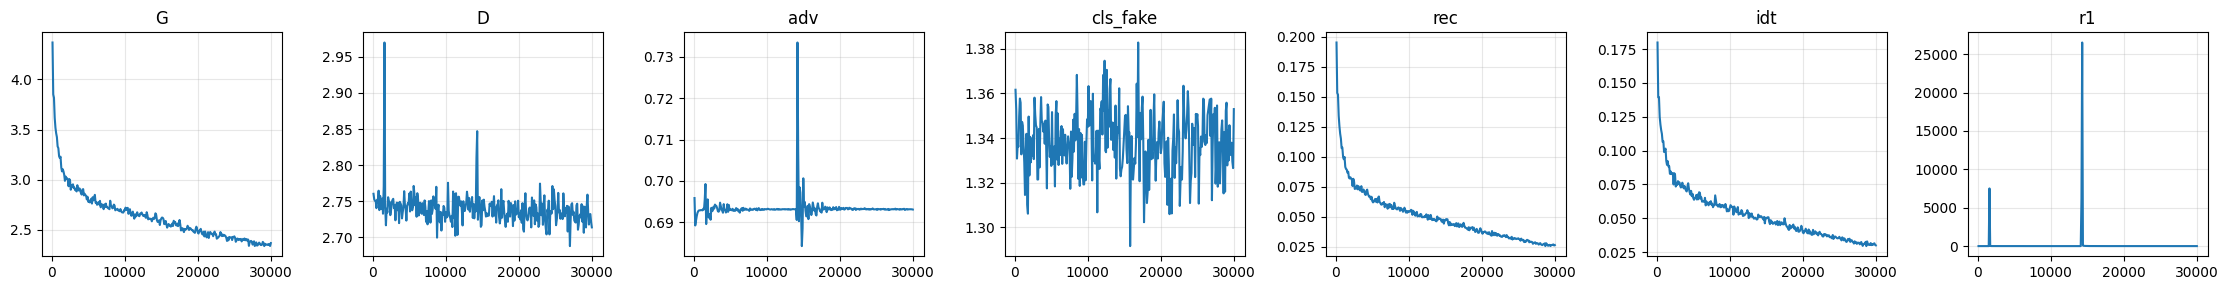

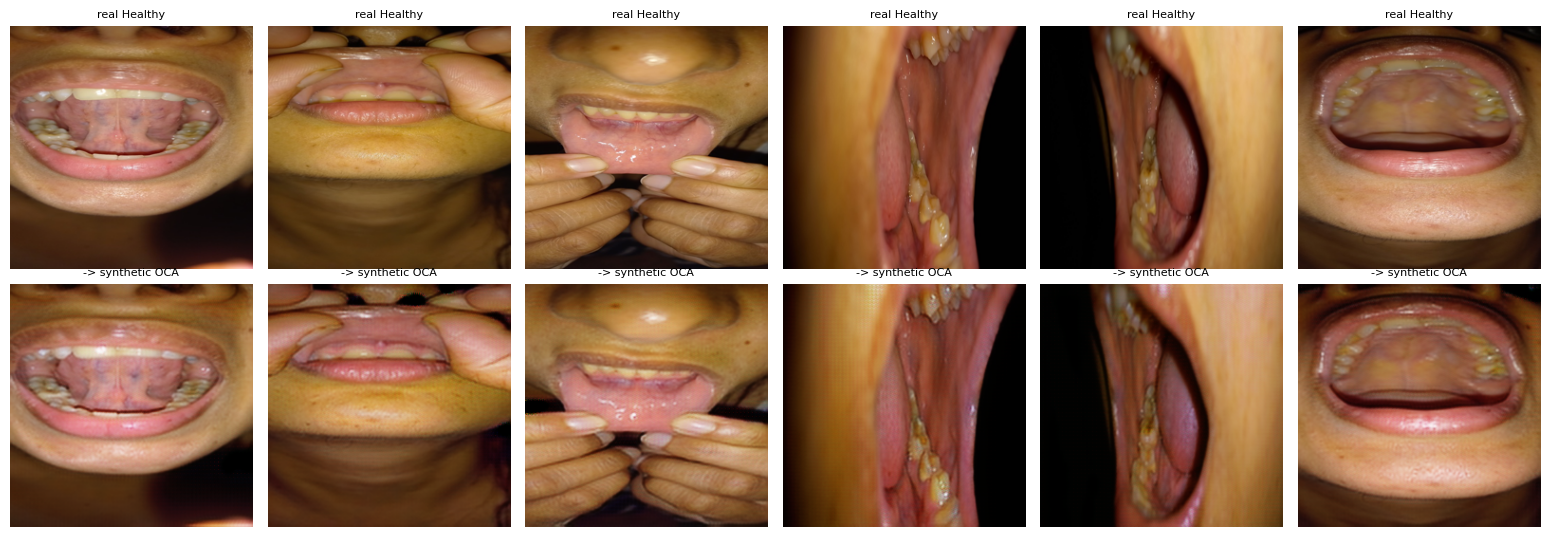

In [8]:
# ============================================================
# 7. LOOK AT THE RESULTS: training curves + before/after pairs
# ============================================================
log_df = pd.DataFrame(logs)
if len(log_df):
    keys = [k for k in log_df.columns if k not in ("iter", "minutes")]
    fig, axes = plt.subplots(1, len(keys), figsize=(3.2 * len(keys), 3))
    for ax, k in zip(np.atleast_1d(axes), keys):
        ax.plot(log_df["iter"], log_df[k]); ax.set_title(k); ax.grid(alpha=.3)
    plt.tight_layout(); fig.savefig(OUT_DIR / "train_curves.png", dpi=120); plt.show()

n_show = min(6, len(src_df))
fig, axes = plt.subplots(2, n_show, figsize=(2.6 * n_show, 5.4), squeeze=False)
for j in range(n_show):
    axes[0, j].imshow(Image.open(src_df.path[j]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    axes[1, j].imshow(Image.open(OUT_DIR / "raw" / f"SYN-{GAN_TYPE}-{j:05d}.png"))
    axes[0, j].set_title(f"real {SOURCE_CLASS}", fontsize=8); axes[1, j].set_title(f"-> synthetic {TARGET_CLASS}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); fig.savefig(OUT_DIR / "before_after.png", dpi=120); plt.show()

## What to check, and what to do next
- **`samples/iterXXXXXX.png`** — rows = 4 fixed healthy photos. CycleGAN: source | OCA.
  StarGAN: source | Benign | Healthy | OCA | OPMD. The anatomy should stay the same while the mucosa changes;
  the OCA column should differ from the OPMD column **in the tissue, not only in the teeth**.
- **Warning signs:** all outputs identical (mode collapse), colour washed out, checkerboard artefacts,
  or the OCA column only blackening teeth (the shortcut seen with diffusion).
- **Next:** notebook 03 with `GENERATOR = "folder"`, `RAW_DIR = <this run>/raw`, `MODE_TAG = "stargan"` /
  `"cyclegan"` → accepted images → notebook 04 (experiments `E5_real_synth_cyclegan`, `E6_real_synth_stargan`).
- **Note:** a translation GAN gives one OCA image per healthy training photo (~481). That is enough for
  `SYN_RATIO` up to ~4 after quality control.